In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/3")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    proj_root = Path.cwd().resolve()
    if proj_root.name == "3":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 3.2 レジスタ (`x86-64 CPU Registers Architecture`)
## — CPU内部記憶の完全体系・ゼロ拡張の罠・フラグ演算数理と制御レジスタの深淵

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/3/3.2_x86_64_Registers.ipynb)

本節は、『ゼロからのOS自作入門』**第3章 画面表示の練習とブートローダ**の第2節 **「3.2 レジスタ」** に対応する完全自己完結型解説ノートブックです。

前節（3.1 QEMUモニタ）では、カーネル起動直後のベアメタル環境において、QEMUモニタの `info registers` や `xp` コマンドを用いて CPU の内部状態と物理メモリを非侵襲に観測する手法を学びました。
モニタ画面には `RAX=...`、`RIP=...`、`CR0=...` といった無数の英数字が出力されましたが、**「それぞれのレジスタが何のために存在し、OS にとってどのような決定的な意味を持つのか」** を知らなければ、デバッグ情報を正しく解読することはできません。

CPU（Central Processing Unit: 中央演算処理装置）にとって、レジスタは思考を行うための**「脳の作業領域そのもの」**です。
本節では、64ビット x86-64 アーキテクチャにおける**汎用レジスタ（GPR）の完全な部分アクセス構造**、**32ビット書き込み時に発動する「ゼロ拡張（Zero-Extension）」の歴史的背景と落とし穴**、**命令ポインタ（RIP）とスタックポインタ（RSP）のメモリ動作**、**フラグレジスタ（RFLAGS）の算術更新の数理導出**、そして**OSの保護・ページングを司る制御レジスタ（CR0〜CR4, CR8）とMSR（IA32_EFER）**の全貌を徹底的に解明します。

---

### 🎯 本節の到達目標 (Learning Objectives)

1. **メモリ階層とレジスタの存在意義の理解**:
   - なぜ CPU はメモリだけで動作せず、レジスタを必要とするのか？（フォン・ノイマン・ボトルネックとクロックサイクル速度差の定量的比較）。
2. **64ビット汎用レジスタ（GPR: RAX〜R15）の階層構造把握**:
   - 64-bit、32-bit、16-bit、8-bit（Low/High）の下位レジスタ命名規則と、伝統的レジスタ（RAX〜RSP）と新設レジスタ（R8〜R15）の決定的な違い。
3. **超重要規則「32ビット書き込み時の上位ゼロ拡張」の完全習得**:
   - `MOV EAX, ...` を実行すると上位32ビットがなぜ自動的にゼロクリアされるのか？ 一方で 16ビット・8ビット書き込みではなぜ上位ビットが保持されるのか？
4. **特殊レジスタ（RIP, RSP, RBP）とスタック動作の数理**:
   - 命令フェッチと RIP 相対アドレッシング、LIFO スタック（`PUSH` / `POP`）による RSP の 8 バイト単位の遷移と 16 バイト整列規約。
5. **RFLAGS フラグレジスタの全ビット配置と算術演算フラグ更新の数理導出**:
   - CF（キャリー）、ZF（ゼロ）、SF（サイン）、OF（オーバーフロー）、PF（パリティ）の論理条件式とアセンブリ分岐命令（`Jcc`）との対応。
6. **制御レジスタ（CR0, CR2, CR3, CR4, CR8）と MSR（IA32_EFER）の理解**:
   - 保護モード有効化（PE）、ページング有効化（PG）、書き込み禁止（WP）、PML4 テーブル基準アドレス（CR3）、Long Mode 有効化（LME/LMA/NXE）。
7. **System V AMD64 ABI 呼び出し規約（Calling Convention）の基礎**:
   - 関数引数渡しレジスタ（RDI, RSI, RDX, RCX, R8, R9）と Caller-saved / Callee-saved の役割分担。


## 1. なぜレジスタが必要なのか？（動機とメモリ階層）

コンピュータの基本構造である**フォン・ノイマン型アーキテクチャ (*von Neumann architecture*)** では、プログラム（機械語命令）とデータはともにメインメモリ（DRAM: *Dynamic Random Access Memory*）に格納されます。

では、なぜ CPU はメモリ上の変数を直接読み書きして計算するのではなく、わざわざ内部に少数の**「レジスタ (*Register*)」**を持っているのでしょうか？

最大の理由は、**「CPUの演算速度」と「メインメモリのアクセス速度」の間に存在する絶望的な性能格差（フォン・ノイマン・ボトルネック: *von Neumann Bottleneck*）** にあります。

```text
+-------------------------------------------------------------------------+
|                  現代のコンピュータにおけるメモリ階層ピラミッド                   |
+-------------------------------------------------------------------------+
|     [ レジスタ (Registers) ]          容量: 数百バイト  | レイテンシ: < 0.5 ns (1 cycle)    |
|        [ L1 キャッシュ ]              容量: 32〜64 KB  | レイテンシ: ~1 ns (4〜5 cycles)   |
|           [ L2 キャッシュ ]           容量: 512KB〜1MB  | レイテンシ: ~3〜4 ns (12 cycles)  |
|              [ L3 キャッシュ ]        容量: 8〜64 MB   | レイテンシ: ~10〜20 ns (40 cycles)|
|                 [ メインメモリ (DRAM) ] 容量: 数GB〜数TB | レイテンシ: ~60〜100 ns (200 cycles)|
+-------------------------------------------------------------------------+
```

### 1.1 サイクル数で考えるアクセスコストの格差

現代の x86-64 CPU は 3.0 GHz 〜 5.0 GHz（1クロック＝約 0.2 〜 0.3 ナノ秒）という超高速で動作しています。
- **レジスタアクセス**: CPU コア内のフリップフロップ回路に直結しているため、**0 クロック（1 サイクル未満）** で即座に値を演算器（ALU: *Arithmetic Logic Unit*）へ供給できます。
- **メインメモリアクセス**: マザーボードのメモリバス配線を経由し、メモリコントローラを介して DRAM のキャパシタにアクセスする必要があるため、どんなに高速な DDR4/DDR5 メモリであっても **100 〜 300 クロックサイクル以上** の待機時間（ストール: *Pipeline Stall*）が発生します。

もし CPU がすべての加算や比較をメインメモリに対して直接行っていたら、CPU の演算ユニットは稼働時間の 99% 以上を「メモリからのデータ到着待ち」で空転することになります。
そのため、CPU は**「いま計算に使うごく少数のデータだけを最寄りのレジスタにロード（`MOV`）し、超高速に計算して、最後に結果をメモリへ書き戻す」**という方式をとっているのです。


## 2. 64ビット汎用レジスタ（GPR: General-Purpose Registers）の完全体系

x86-64 アーキテクチャには、プログラムが自由に演算やアドレス計算に使用できる**16本の 64ビット汎用レジスタ (*General-Purpose Registers: GPR*)** が存在します。

これらは歴史的経緯により、以下の2グループに大別されます：
1. **伝統的レジスタ群 (8本)**: 16ビット（8086）→ 32ビット（IA-32 / 80386）→ 64ビット（x86-64 / AMD64）と段階的に拡張されてきたレジスタ。
   - `RAX`, `RBX`, `RCX`, `RDX`, `RSI`, `RDI`, `RBP`, `RSP`
2. **x86-64 拡張レジスタ群 (8本)**: 64ビット化の際に AMD が新設したレジスタ。
   - `R8`, `R9`, `R10`, `R11`, `R12`, `R13`, `R14`, `R15`

### 2.1 レジスタの部分アクセス構造と名称マッピング

x86-64 では、64ビットレジスタ全体だけでなく、過去の 32ビットコード、16ビットコード、8ビットコードとの下位互換性およびデータ幅に応じた最適化のため、**レジスタの下位 32ビット、下位 16ビット、下位 8ビットを独立した名前で個別に読み書き**できます。

| 64-bit 全体 (Quadword) | 32-bit 下位 (Doubleword) | 16-bit 下位 (Word) | 8-bit 下位 (Byte Low) | 8-bit 上位 (Byte High) | 伝統的な主な用途・ABI規約上の役割 |
|:---:|:---:|:---:|:---:|:---:|---|
| **`RAX`** | `EAX` | `AX` | `AL` | `AH` | アキュムレータ (*Accumulator*) / 関数戻り値 1 |
| **`RBX`** | `EBX` | `BX` | `BL` | `BH` | ベースレジスタ (*Base*) / Callee-saved |
| **`RCX`** | `ECX` | `CX` | `CL` | `CH` | カウンタ (*Counter*) / シフト演算数 / 第4引数 |
| **`RDX`** | `EDX` | `DX` | `DL` | `DH` | データレジスタ (*Data*) / 乗除算余り / 第3引数 / 関数戻り値 2 |
| **`RSI`** | `ESI` | `SI` | `SIL` | なし | ソースインデックス (*Source Index*) / 文字列元 / 第2引数 |
| **`RDI`** | `EDI` | `DI` | `DIL` | なし | デストインデックス (*Destination Index*) / 文字列先 / 第1引数 |
| **`RBP`** | `EBP` | `BP` | `BPL` | なし | ベースポインタ (*Base Pointer*) / スタックフレーム底 |
| **`RSP`** | `ESP` | `SP` | `SPL` | なし | スタックポインタ (*Stack Pointer*) / スタック最上位 |
| **`R8`**  | `R8D` | `R8W` | `R8B` | なし | 拡張レジスタ 8 / 第5引数 |
| **`R9`**  | `R9D` | `R9W` | `R9B` | なし | 拡張レジスタ 9 / 第6引数 |
| **`R10`** | `R10D` | `R10W` | `R10B` | なし | 拡張レジスタ 10 / システムコール一時退避 |
| **`R11`** | `R11D` | `R11W` | `R11B` | なし | 拡張レジスタ 11 / `RFLAGS` 一時退避 |
| **`R12`** | `R12D` | `R12W` | `R12B` | なし | 拡張レジスタ 12 / Callee-saved |
| **`R13`** | `R13D` | `R13W` | `R13B` | なし | 拡張レジスタ 13 / Callee-saved |
| **`R14`** | `R14D` | `R14W` | `R14B` | なし | 拡張レジスタ 14 / Callee-saved |
| **`R15`** | `R15D` | `R15W` | `R15B` | なし | 拡張レジスタ 15 / Callee-saved |

> [!NOTE]
> **上位 8ビット（High Byte: `AH`, `BH`, `CH`, `DH`）の特殊性**:
> レジスタのビット 8〜15 に直接アクセスできる High-Byte レジスタは、初代 8086 から存在する `RAX`〜`RDX` の 4 本にのみ存在します。`RSI`, `RDI`, `RBP`, `RSP` や拡張レジスタ `R8`〜`R15` には High-Byte サブレジスタは存在しません（低位 8ビットのみアクセス可能）。


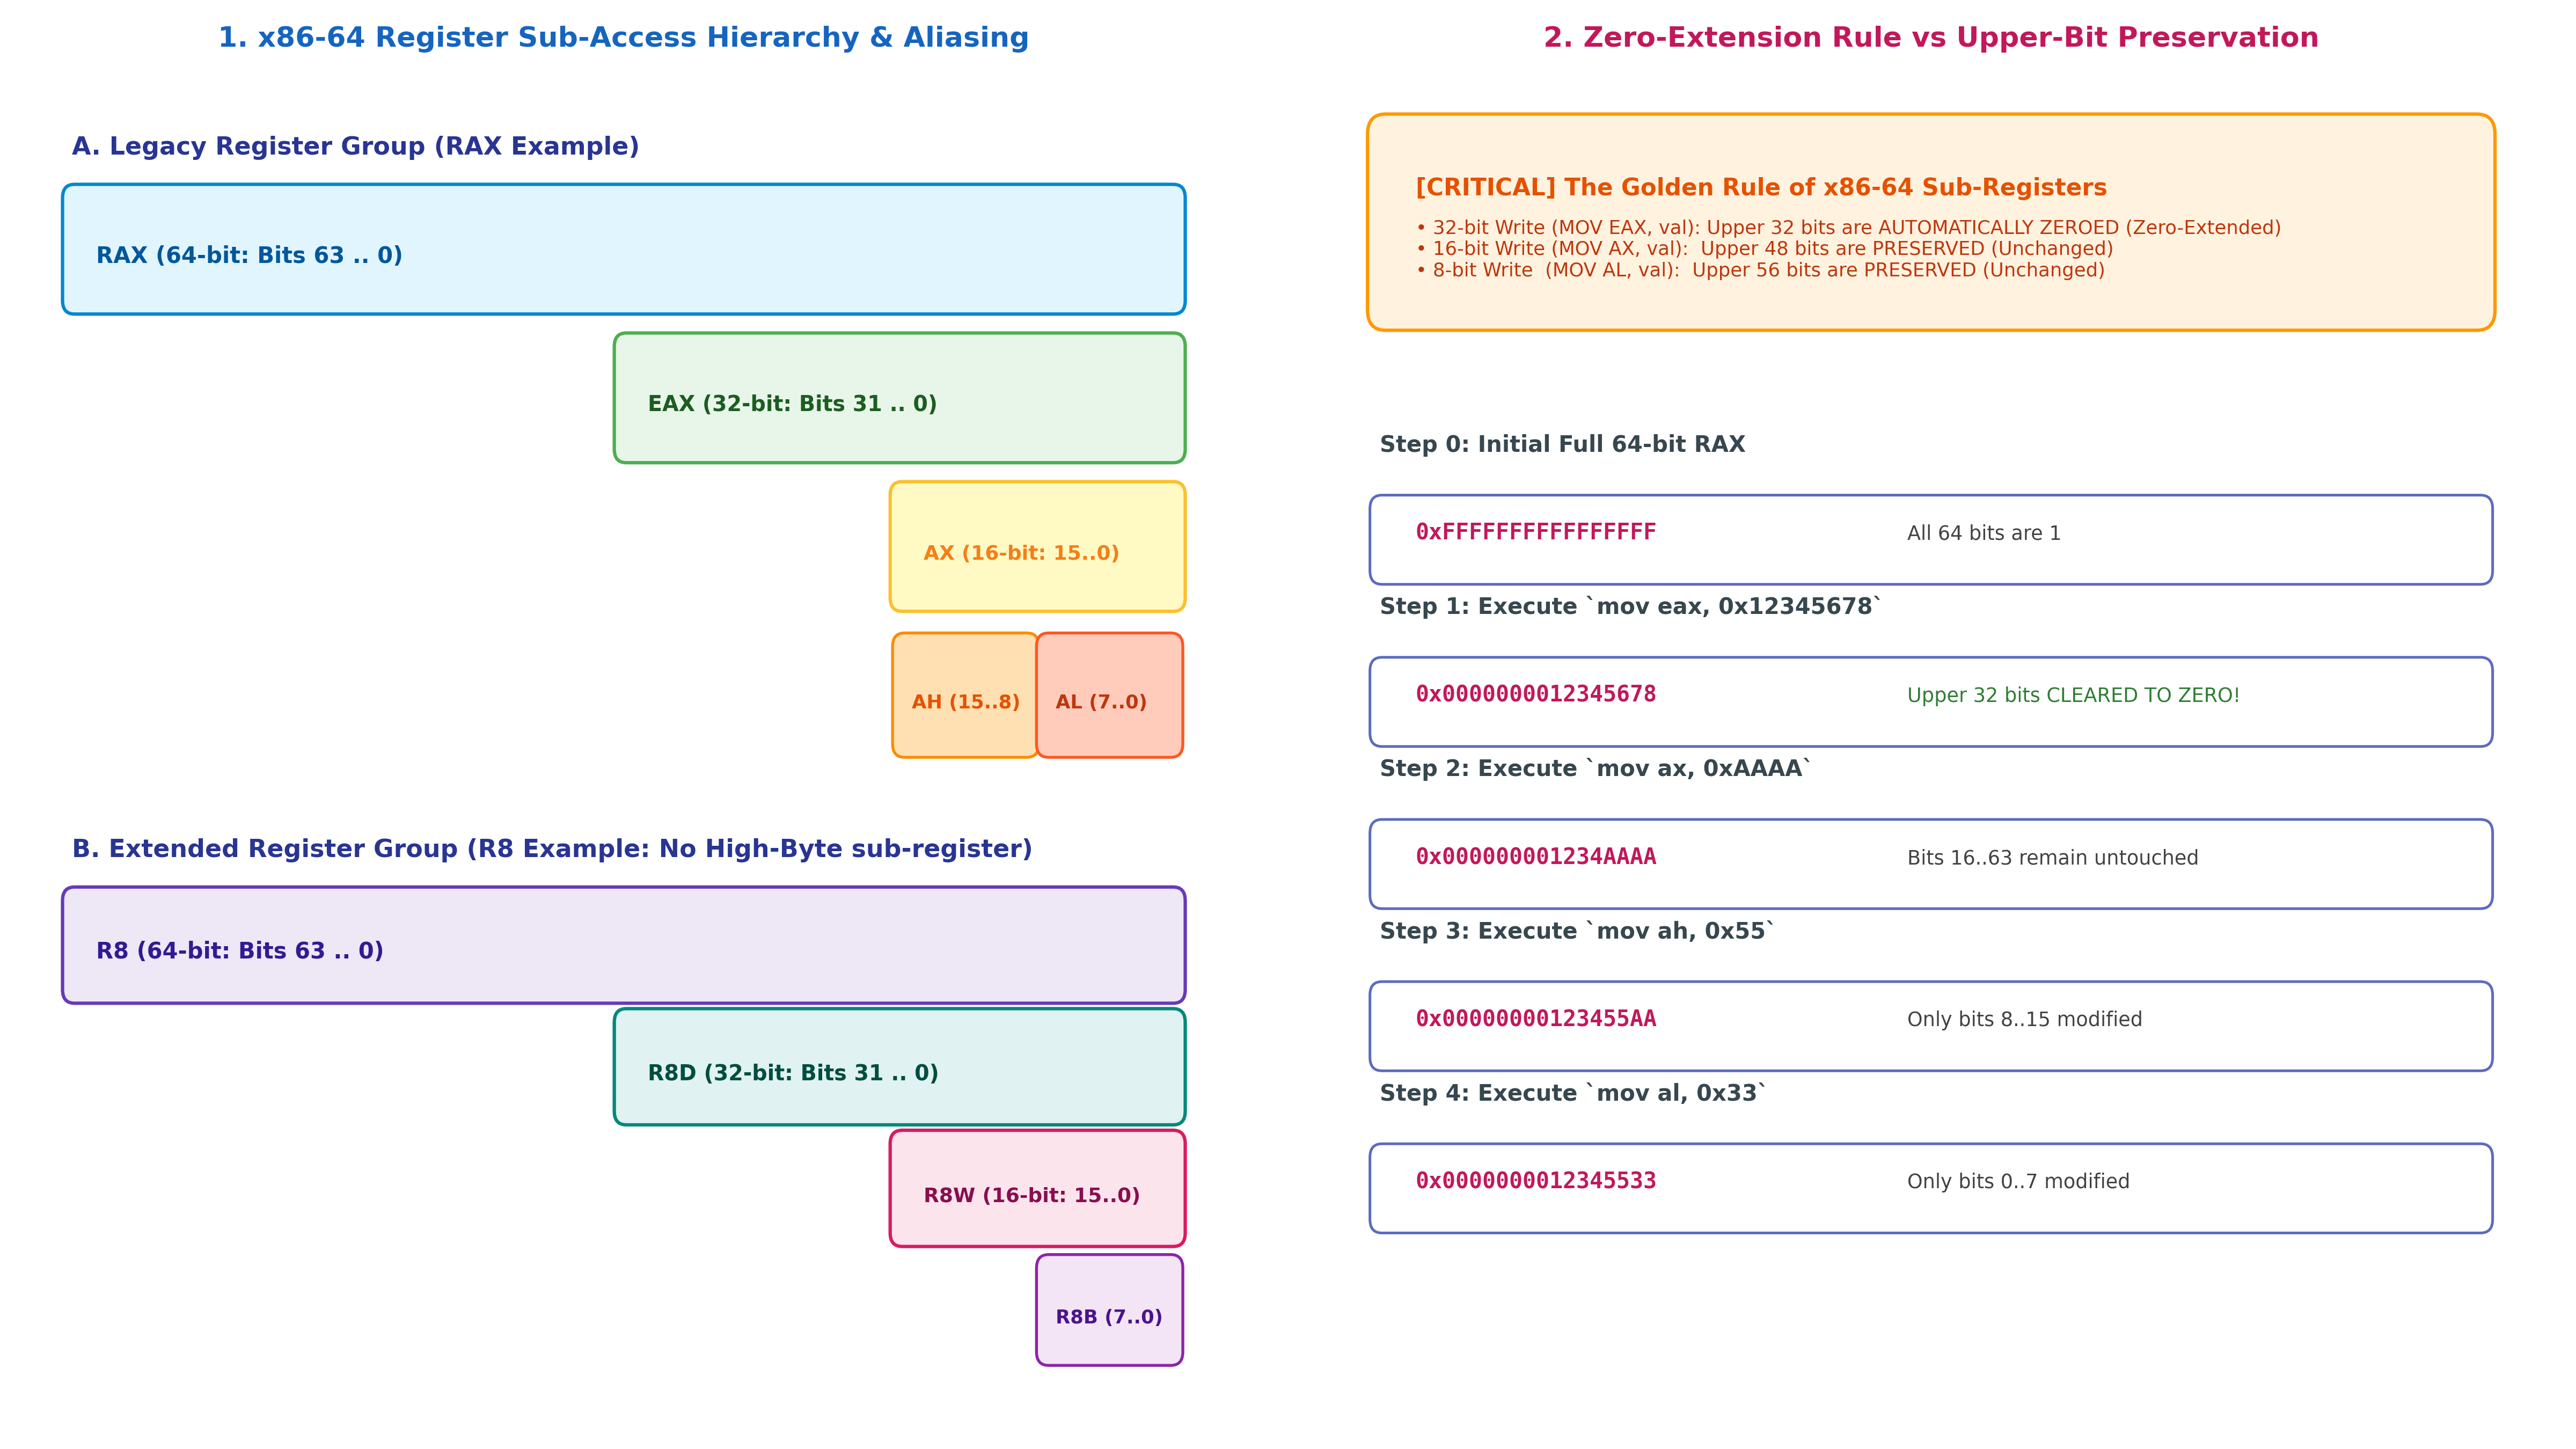

In [2]:
from pathlib import Path
from common import plot_x86_64_register_hierarchy
from IPython.display import Image, display

fig_path = Path("result/fig3_03_x86_64_register_hierarchy.png")
plot_x86_64_register_hierarchy(fig_path)
display(Image(filename=str(fig_path)))


## 3. 超重要規則: 32ビット書き込み時の上位ゼロ拡張 (Zero-Extension Rule)

低レイヤプログラミングや OS 自作において、**「最も多くのエンジニアが一度は引っかかる最大の罠」**がこの規則です。

> [!IMPORTANT]
> **x86-64 アーキテクチャの絶対規則（Zero-Extension Rule）**:
> 1. **32ビットレジスタへの書き込み（例: `MOV EAX, 0x12345678`）を行うと、対応する 64ビットレジスタの上位 32ビット（Bits 32〜63）は自動的に「すべて 0 にクリア（ゼロ拡張）」される！**
> 2. **一方、16ビットレジスタ（`AX`）や 8ビットレジスタ（`AL`, `AH`）への書き込みでは、上位ビット（Bits 16〜63 や Bits 8〜63）は以前の値をそのまま保持する（変更されない）！**

### 3.1 なぜ 32ビット書き込みだけゼロ拡張されるのか？（設計思想）

一見すると「すべてのサイズで上位ビットを維持する」か「すべてのサイズでゼロ拡張する」方が対称的で分かりやすいように思えます。なぜこのような一見非対称な仕様になったのでしょうか？

これには、CPU の**アウト・オブ・オーダー実行 (*Out-of-Order Execution*)** と **レジスタ・リネーミング (*Register Renaming*)** における深い技術的理由があります。

1. **偽のデータ依存性（False Data Dependency: WAW/WARハザード）の解消**:
   もし 32ビットレジスタへの書き込みで上位 32ビットを保持しなければならないとすると、CPU は新しい 32ビット値を書き込む前に「直前の 64ビットレジスタの上位 32ビットの値が何だったか」を待たなければならなくなります。
   これにより、本来無関係な命令同士の間に直列化（依存関係チェーン）が発生し、スーパースケーラ CPU の並列実行性能が大きく低下します。
2. **上位 32ビットを 0 クリアすると割り切るメリット**:
   「32ビットレジスタへの書き込みは、64ビットレジスタ全体への新しい代入である」と定義することで、CPU は過去の上位 32ビット値への依存を完全に断ち切り、新しい物理レジスタを即座に割り当てて並列実行できるようになります。
3. **なぜ 16ビット / 8ビットは上位維持のままなのか？**:
   8086 時代のコード（例: `AH` に文字コード、`AL` に属性を入れて 1 つの 16ビットワード `AX` を合成する手法など）との完全な後方互換性を壊さないため、16ビット・8ビットへの書き込みは上位維持の挙動が残されました。

```text
初期状態: RAX = 0xFFFFFFFFFFFFFFFF (全64ビットが 1)

1. MOV EAX, 0x12345678 を実行:
   +--------------------------------+--------------------------------+
   | Bits 63..32: 0x00000000 (自動クリア) | Bits 31..0:  0x12345678        |
   +--------------------------------+--------------------------------+
   => RAX は 0x0000000012345678 となる！ (上位32ビットの 0xFFFFFFFF は消滅)

2. 続いて MOV AX, 0xAAAA を実行 (16ビット書き込み):
   +--------------------------------+--------------------------------+
   | Bits 63..32: 0x00000000 (維持)  | Bits 31..16: 0x1234 (維持)     | Bits 15..0: 0xAAAA (更新) |
   +--------------------------------+--------------------------------+
   => RAX は 0x000000001234AAAA となる！ (上位48ビットは保持される)
```


## 4. 特殊レジスタ: 命令ポインタ (RIP) とスタックポインタ (RSP)

汎用レジスタとは異なり、CPU の実行制御そのものを担う不可欠なレジスタが **`RIP`** と **`RSP`** です。

### 4.1 命令ポインタ (RIP: Instruction Pointer)

`RIP`（32ビット時代は `EIP`、16ビット時代は `IP`）は、**「CPUが次にフェッチ（読み出し）して実行する機械語命令のメモリ先頭アドレス」** を保持する 64ビットレジスタです。

- 通常、命令が実行されるたびに `RIP` はその命令のバイト長（1〜15バイト）だけ自動的に加算されます。
- `JMP`, `CALL`, `RET`, 条件分岐命令（`JZ`, `JNZ` 等）が実行されると、`RIP` に新しいジャンプ先アドレスが上書きされ、実行の流れが切り替わります。
- **RIP 相対アドレッシング (*RIP-Relative Addressing*)**:
  x86-64 では、コードとデータの位置独立性（PIC: *Position Independent Code*）を高めるため、`[RIP + オフセット]` 形式で現在の命令位置からの相対オフセットでメモリ変数を参照する命令が多用されます。

### 4.2 スタックポインタ (RSP: Stack Pointer) と LIFO スタック

`RSP` は、メインメモリ上に確保された**「コールスタック（LIFO: *Last-In, First-Out* 後入れ先出し構造）」の最上位アドレス（スタックトップ）** を指すポインタです。

x86-64 のスタックは、**「高位アドレスから低位アドレスに向かって下向きに成長（*grows downward*）」** します。

```text
    高位アドレス (0x07FE3DC0)
          |   +--------------------------+
          |   |  直前のスタックフレーム  |
          |   +--------------------------+
          |   |  引数 / 退避レジスタ     |
          v   +--------------------------+  <-- RSP (初期位置: 0x07FE3DC0)
              |  PUSH された 64-bit 値   |  <-- RSP (PUSH 後: 0x07FE3DB8 = RSP - 8)
    低位アドレス +--------------------------+
```

1. **`PUSH val` 命令の動作**:
   - `RSP` を 8 バイト減算する: $RSP \leftarrow RSP - 8$
   - 減算後の `[RSP]` のアドレスに 64ビット値 `val` を書き込む。
2. **`POP reg` 命令の動作**:
   - 現在の `[RSP]` のアドレスから 64ビット値を読み出し、レジスタ `reg` に格納する。
   - `RSP` を 8 バイト加算する: $RSP \leftarrow RSP + 8$
3. **スタックのアライメント要件（System V AMD64 ABI）**:
   - 関数呼び出し命令 `CALL` を実行する直前の時点で、**`RSP` は必ず 16 バイト境界に整列（$RSP \pmod{16} == 0$）していなければならない**という厳格な規約があります。
   - `CALL` 命令が戻り先アドレス（8バイト）をスタックに `PUSH` するため、**関数エントリ（関数の先頭命令実行時）では必ず $RSP \pmod{16} == 8$ になります**。このアライメントが崩れると、SSE などの 128ビットベクトル命令（`movaps` 等）が一般保護例外（`#GP`）を起こしてカーネルがクラッシュします。


## 5. フラグレジスタ (RFLAGS) と算術ステータスフラグの数理導出

`RFLAGS` は、直前の算術・論理演算の結果や、CPU の動作状態・割り込み許可状態を保持する 64ビットレジスタです（下位 32ビットを `EFLAGS`、下位 16ビットを `FLAGS` と呼びます）。

```text
 63                                22 21 20 19 18 17 16 15 14 13 12 11 10  9  8  7  6  5  4  3  2  1  0
+------------------------------------+--+--+--+--+--+--+--+--+-----+--+--+--+--+--+--+--+--+--+--+--+--+
|            Reserved (0)            |ID|VI|VF|AC|VM|RF| 0|NT| IOPL|OF|DF|IF|TF|SF|ZF| 0|AF| 0|PF| 1|CF|
+------------------------------------+--+--+--+--+--+--+--+--+-----+--+--+--+--+--+--+--+--+--+--+--+--+
```

### 5.1 主要ステータスフラグ（Status Flags）と数学的計算式

2つの $n$ ビット整数 $A, B$ に対する演算結果を $R$（符号なし）、符号付き解釈を $sA, sB, sR$ とします。

1. **CF (Carry Flag: ビット 0)** — 符号なし演算の桁あふれ / 桁借り:
   - 加算 ($R = A + B$): $R < A$ または $A + B \ge 2^n$ のとき $CF = 1$
   - 減算 ($R = A - B$): $A < B$（桁借り発生）のとき $CF = 1$
2. **ZF (Zero Flag: ビット 6)** — 演算結果がゼロ:
   - $ZF = 1 \iff R == 0$
3. **SF (Sign Flag: ビット 7)** — 演算結果の最上位ビット（MSB / 符号ビット）:
   - $SF = 1 \iff (R 	ext{ bit } (n-1)) == 1$（負数）
4. **OF (Overflow Flag: ビット 11)** — 符号付き演算の桁あふれ:
   - 正と正を足して負になった、または負と負を足して正になった場合に発生：
     $$OF = (sA > 0 \land sB > 0 \land sR < 0) \lor (sA < 0 \land sB < 0 \land sR > 0)$$
   - 減算の場合：$OF = (sA \ge 0 \land sB < 0 \land sR < 0) \lor (sA < 0 \land sB \ge 0 \land sR \ge 0)$
5. **PF (Parity Flag: ビット 2)** — パリティフラグ:
   - 演算結果の**最下位 8 ビット（Bits 0〜7）に含まれる '1' の個数が偶数個であれば 1、奇数個であれば 0**。通信エラーチェックの名残です。
6. **IF (Interrupt Enable Flag: ビット 9)** — 割り込み許可フラグ:
   - $IF = 1$ のとき CPU は外部ハードウェア割り込みを受け付けます（`STI` 命令で 1 に設定、`CLI` 命令で 0 に設定）。
7. **予約ビット 1 (Bit 1 = 1)**:
   - x86 アーキテクチャの歴史的仕様により、**ビット 1 は常に 1** で固定されています。


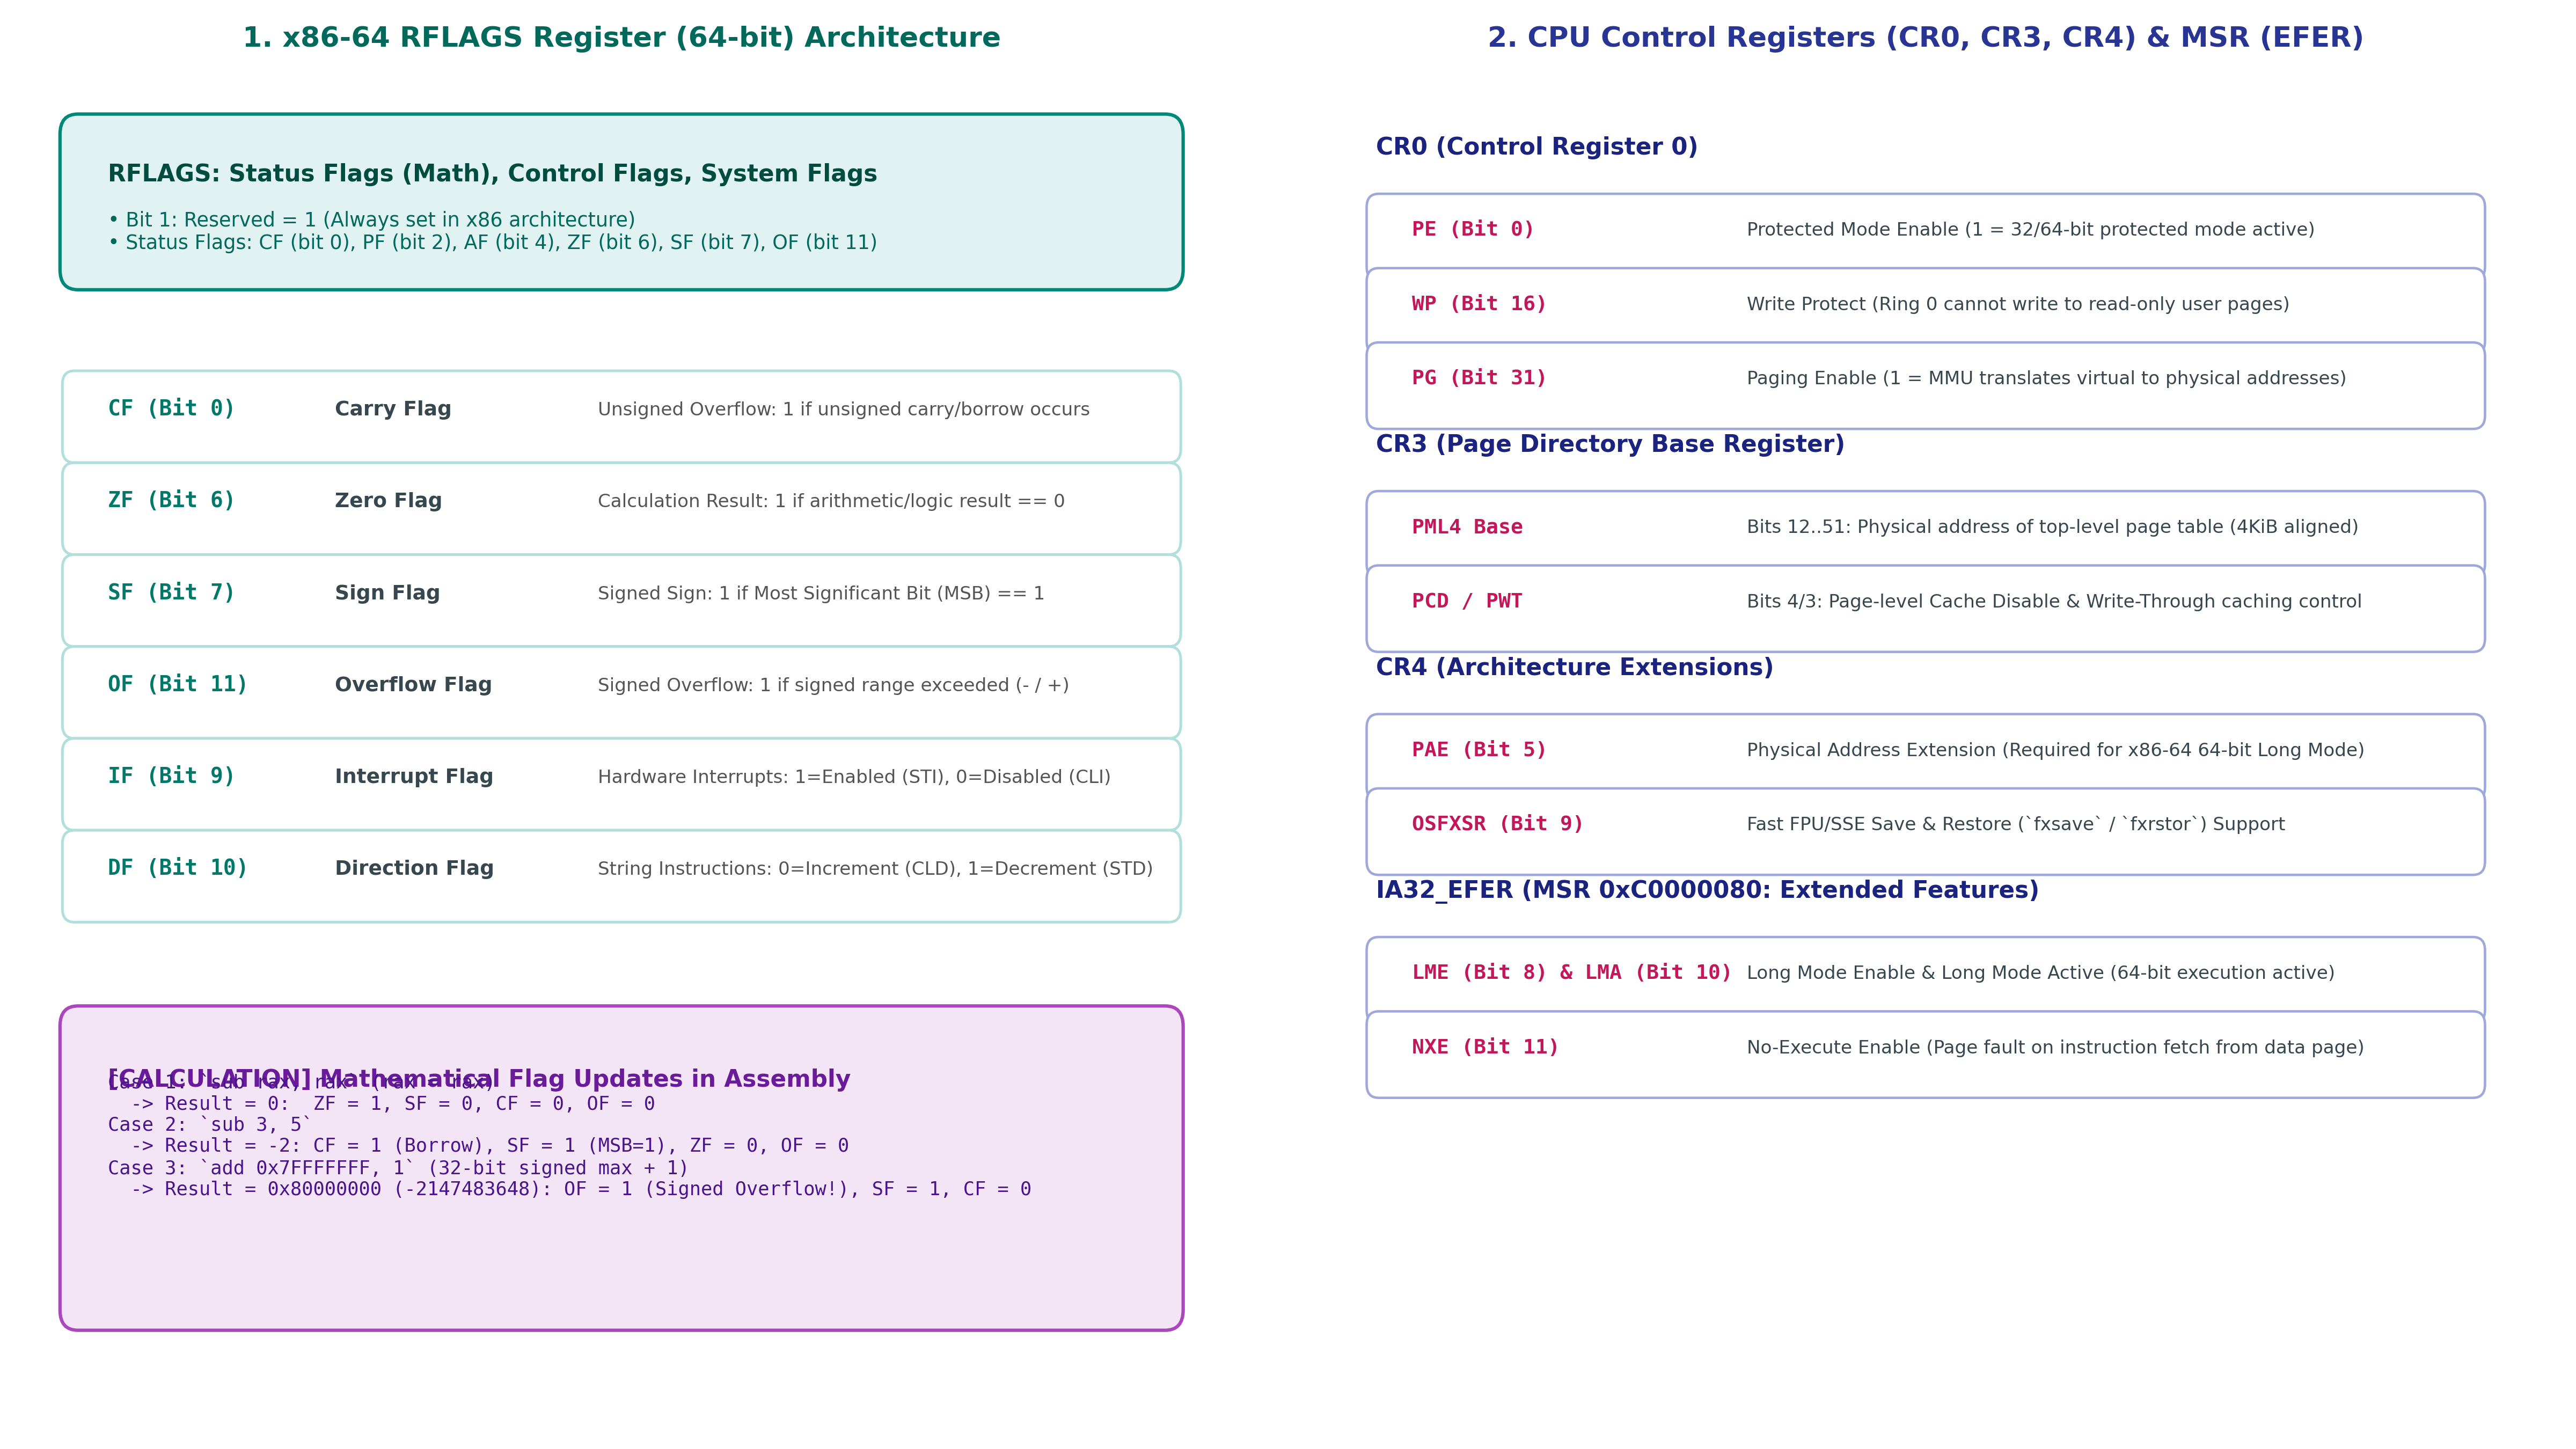

In [3]:
from pathlib import Path
from common import plot_rflags_and_control_registers
from IPython.display import Image, display

fig_path = Path("result/fig3_04_rflags_and_control_registers.png")
plot_rflags_and_control_registers(fig_path)
display(Image(filename=str(fig_path)))


## 6. 制御レジスタ (CR0〜CR4, CR8) と MSR (IA32_EFER)

汎用レジスタや RFLAGS が「アプリケーションの計算」に関わるのに対し、**制御レジスタ (*Control Registers: CR0..CR4, CR8*)** は「CPU 本体の動作モードやハードウェア保護機能、仮想記憶」を直接切り替えるための**OSカーネル専用の特権レジスタ**です。

### 6.1 CR0: CPU の中核動作モード制御

- **PE (Protection Enable: ビット 0)**:
  $PE = 1$ で CPU は 16ビットリアルモードから 32ビット保護モード / 64ビットロングモードに遷移します。
- **WP (Write Protect: ビット 16)**:
  $WP = 1$ のとき、特権レベル Ring 0（カーネルモード）であってもユーザー空間の読み取り専用ページへの書き込みがハードウェアによってブロックされます。OSのセキュリティ（悪意あるアプリによるカーネル改ざん防止）や Copy-on-Write（CoW）機構の実装に必須です。
- **PG (Paging: ビット 31)**:
  $PG = 1$ で MMU による仮想アドレスから物理アドレスへのページング変換が有効化されます。

### 6.2 CR2 と CR3: ページングと仮想記憶の要

- **CR2 (Page Fault Linear Address Register)**:
  ページフォルト例外（`#PF`: ベクタ 14）が発生した際、CPU が**「アクセスに失敗した仮想アドレス（リニアアドレス）」**を自動的にこのレジスタに書き込みます。OSのページフォルトハンドラは `CR2` を読むことで、オンデマンドページングやスタック自動拡張を処理します。
- **CR3 (Page Directory Base Register: PDBR)**:
  x86-64 の 4階層ページングにおける最上位ページテーブル**「PML4 (Page Map Level 4) テーブルの物理先頭アドレス（Bits 12〜51）」**を保持します。
  タスクごとに異なる `CR3` を設定することで、プロセス間の完全なメモリ空間分離が実現されます。

### 6.3 CR4 と MSR (IA32_EFER)

- **CR4 ビット 5 (PAE: Physical Address Extension)**:
  64ビットロングモードを動かすためには必ず $PAE = 1$ でなければなりません。
- **CR4 ビット 9 (OSFXSR: Fast FPU/SSE Save & Restore)**:
  $OSFXSR = 1$ にすることで、マルチタスク時のコンテキストスイッチ命令 `fxsave` / `fxrstor` が有効化されます。
- **MSR `IA32_EFER` (Model Specific Register: 0xC0000080)**:
  - **LME (Long Mode Enable: ビット 8)**: 64ビットロングモードの有効化要求。
  - **LMA (Long Mode Active: ビット 10)**: CPU が実際に 64ビットモードで動作していることを示すステータス。
  - **NXE (No-Execute Enable: ビット 11)**: ページテーブルエントリの XD（Execute-Disable）ビットを有効化し、データ領域（スタックやヒープ）でのコード実行（バッファオーバーフロー攻撃）を CPU レベルで阻止します。


## 7. セグメントレジスタと System V AMD64 ABI 呼び出し規約

### 7.1 64ビットモードにおけるセグメントレジスタ (CS, DS, SS, ES, FS, GS)

16ビット/32ビット時代、メモリ空間の分割とアクセス制御は「セグメンテーション（GDT: *Global Descriptor Table*）」によって行われていました。
しかし、64ビット Long Mode では、メモリ管理の主役は完全に「ページング」へと移行し、**セグメンテーションは事実上フラット化（ベースアドレス 0、リミット無効）** されました。

- **`CS` (Code Segment)**: ベースアドレスは 0 固定ですが、下位 2 ビット（CPL: *Current Privilege Level*）が現在の特権レベル（`00` = Ring 0 カーネル, `11` = Ring 3 ユーザー）を決定する重要な役割を残しています。
- **`FS` / `GS`**: 唯一ベースアドレスを自由に設定できる例外セグメントです。MSR（`IA32_FS_BASE` / `IA32_GS_BASE`）を通じてスレッド局所ストレージ（TLS: *Thread Local Storage*）や CPU 固有データ構造体のベースアドレスとして利用されます。

### 7.2 System V AMD64 ABI 呼び出し規約（Calling Convention）

C/C++ プログラムが関数を呼び出す際、「どのレジスタに引数を入れ、どのレジスタに戻り値が返り、どのレジスタの値を破壊してよいのか」を取り決めた標準仕様が **System V AMD64 ABI** です。

```text
関数呼び出し例: int64_t my_func(a, b, c, d, e, f, g);
  第1引数 (a): RDI
  第2引数 (b): RSI
  第3引数 (c): RDX
  第4引数 (d): RCX
  第5引数 (e): R8
  第6引数 (f): R9
  第7引数以降 (g): スタックに PUSH
戻り値:
  RAX (整数・ポインタ), RDX (128ビット整数の上位)
```

- **呼び出し側退避レジスタ（Caller-Saved / 揮発性 Scratch Registers）**:
  `RAX`, `RCX`, `RDX`, `RSI`, `RDI`, `R8`, `R9`, `R10`, `R11`
  - 呼び出された関数が自由に変更してよいレジスタ。呼び出し元が値を維持したい場合は自分で退避する必要があります。
- **被呼び出し側退避レジスタ（Callee-Saved / 非揮発性 Preserved Registers）**:
  `RBX`, `RSP`, `RBP`, `R12`, `R13`, `R14`, `R15`
  - 呼び出された関数は、これらのレジスタを変更する場合、関数を抜ける前に必ず元の値に復元しなければなりません。


## 8. C++20 によるレジスタシミュレータの実装と対話検証

ホスト環境（Linux / Colab）上で x86-64 のレジスタファイル、下位サブレジスタのゼロ拡張、LIFO スタック動作、および RFLAGS 算術フラグ計算を検証する C++20 スタンドアロンバイナリ（`src/ch03/registers_sim.cpp`）を実行します。


In [4]:
!cmake -B ../build -S ..
!cmake --build ../build --target ch03_registers_sim
!../build/bin/ch03_registers_sim --test
!../build/bin/ch03_registers_sim


-- Configuring done (0.0s)
-- Generating done (0.0s)
-- Build files have been written to: /home/student/Documents/GitHub/study-mikanos/build


[100%] Built target ch03_registers_sim


[TEST] 1. x86-64 Sub-register Zero-Extension Rule...
  -> PASSED: 32-bit zero-extension and partial sub-register preservation verified.
[TEST] 2. Stack LIFO and 8-byte alignment...
  -> PASSED: Stack push/pop LIFO verified.
[TEST] 3. RFLAGS Status Flag Calculation...
  -> PASSED: RFLAGS status flags arithmetic verified.
[TEST] 4. Control Registers & MSR...
  -> PASSED: Control registers and MSR flags verified.
[TEST] 5. System V AMD64 ABI Calling Convention...
  -> PASSED: System V ABI argument passing verified.

>>> ALL REGISTER SIMULATION TESTS PASSED SUCCESSFULLY! <<<



=== x86-64 Architecture Register Simulator (MikanOS Chapter 3.2) ===
Initial RAX: 0xffffffffffffffff
After MOV EAX, 0x12345678 (Zero-Extension Rule):
  EAX: 0x12345678
  RAX: 0x0000000012345678 (Upper 32 bits cleared!)

Flags after (100 - 100): [PF ZF IF IOPL=0]


## 9. Python による対話型レジスタ・フラグ・ABI 実験

Python 共通シミュレーションライブラリ（`common`）を用いて、レジスタ書き込みによるゼロ拡張の挙動、スタック操作、および System V ABI の引数マッピングを対話的に実験してみましょう。


In [5]:
from common import X86_64RegisterFile, RFlagsRegister, ControlRegisters, CallingConventionSimulator

# 1. 32ビットゼロ拡張の実験
rf = X86_64RegisterFile()
rf.write_64("rax", 0xFFFFFFFFFFFFFFFF)
print(f"初期状態 RAX: 0x{rf.read_64('rax'):016x}")

# 32ビット EAX への書き込み
rf.write_32("eax", 0x12345678)
print(f"MOV EAX, 0x12345678 実行後:")
print(f"  EAX = 0x{rf.read_32('eax'):08x}")
print(f"  RAX = 0x{rf.read_64('rax'):016x} (上位32ビットがゼロクリアされた!)")

# 16ビット AX への書き込み
rf.write_16("ax", 0xAAAA)
print(f"MOV AX, 0xAAAA 実行後:")
print(f"  RAX = 0x{rf.read_64('rax'):016x} (上位48ビットは保持された!)")

# 2. RFLAGS 算術フラグ演算の実験
rfl = RFlagsRegister()
print("\n--- RFLAGS フラグ計算 ---")
# 100 - 100 = 0
rfl.update_arithmetic_sub(100, 100, width=64)
print(f"100 - 100: {rfl.format_flags_summary()}")

# 3 - 5 = -2 (符号なしボロー発生)
rfl.update_arithmetic_sub(3, 5, width=64)
print(f"3 - 5:     {rfl.format_flags_summary()}")

# 3. System V AMD64 ABI 引数配置
print("\n--- System V ABI 引数渡しシミュレーション ---")
sample_args = [0x100, 0x200, 0x300, 0x400, 0x500, 0x600, 0x700, 0x800]
reg_args, stack_args = CallingConventionSimulator.prepare_call(rf, sample_args)
print(f"レジスタ引数 (第1〜6引数): {reg_args}")
print(f"スタック引数 (第7引数以降): {[hex(x) for x in stack_args]}")
print(f"スタックトップ [RSP] から POP: 0x{rf.pop():x}")


初期状態 RAX: 0xffffffffffffffff
MOV EAX, 0x12345678 実行後:
  EAX = 0x12345678
  RAX = 0x0000000012345678 (上位32ビットがゼロクリアされた!)
MOV AX, 0xAAAA 実行後:
  RAX = 0x000000001234aaaa (上位48ビットは保持された!)

--- RFLAGS フラグ計算 ---
100 - 100: [PF ZF IF IOPL=0]
3 - 5:     [CF SF IF IOPL=0]

--- System V ABI 引数渡しシミュレーション ---
レジスタ引数 (第1〜6引数): {'rdi': 256, 'rsi': 512, 'rdx': 768, 'rcx': 1024, 'r8': 1280, 'r9': 1536}
スタック引数 (第7引数以降): ['0x700', '0x800']
スタックトップ [RSP] から POP: 0x800


## 10. 本節のまとめと次節（3.3 初めてのカーネル）への展望

### 📝 本節で学んだ重要概念の総括

1. **メモリ階層とレジスタの意義**:
   - メインメモリの数百クロックサイクルのレイテンシを克服し、CPU が 0 クロックで超高速演算を行うためにレジスタが存在する。
2. **汎用レジスタ（GPR: 16本）の階層構造**:
   - 64ビット `RAX`〜`R15`、32ビット `EAX`〜`R15D`、16ビット `AX`〜`R15W`、8ビット `AL`〜`R15B`。High-Byte レジスタ（`AH`〜`DH`）は伝統的4本のみ。
3. **超重要規則「32ビット書き込み時の上位ゼロ拡張」**:
   - 32ビットサブレジスタへの代入は上位 32ビットを自動的に 0 クリアする。アウト・オブ・オーダー実行時のレジスタリネーミングと偽依存性解消のための設計。
4. **特殊レジスタ（RIP, RSP）**:
   - `RIP` は次に実行する命令アドレスを指す。`RSP` は下向きに成長するスタックの最上位を指し、`PUSH` で 8 減算、`POP` で 8 加算される。ABI の 16バイトアライメント要件が必須。
5. **RFLAGS フラグと算術数理**:
   - キャリー（CF）、ゼロ（ZF）、サイン（SF）、オーバーフロー（OF）の論理演算条件と、予約ビット 1 の歴史的仕様。
6. **制御レジスタ（CR0, CR3, CR4）と MSR（IA32_EFER）**:
   - $PE=1$（保護モード）、$WP=1$（書き込み保護）、$PG=1$（ページング）、$PAE=1$、$CR3$（PML4 テーブル基準アドレス）。
7. **System V AMD64 ABI 呼び出し規約**:
   - 第1〜第6引数は `RDI, RSI, RDX, RCX, R8, R9`、戻り値は `RAX`。

---

### 🚀 次節への予告: 3.3 初めてのカーネル (`First Kernel and Red Zone`)

レジスタの全貌をマスターした次節では、いよいよ EDK II ブートローダから独自の C++ カーネルバイナリをロードし、関数ポインタを介して制御をジャンプさせる**「カーネルの初起動（`osbook_day03a`）」** に挑戦します！

そこでは、UEFI ブートサービスを終了させる `ExitBootServices()` の呼び出し手順、そして C++ コンパイラがスタックの下流に勝手に確保する **「128バイトのレッドゾーン（Red Zone）の罠」** とその回避策（`-mno-red-zone`）の真髄に迫ります。
